# Deep Learning in Engineering

Neural networks are behind most of the recent headlines about artificial intelligence: image recognition, speech assistants, large language models. In engineering, they are used for visual quality inspection, for virtual sensors, for surrogate models of simulations and for predicting the remaining useful life of machines. Their strength is that they can learn suitable features from raw data – pixels, signal samples, sequences – by themselves, where the methods of the previous chapters needed hand-crafted features.

This chapter gives a compact, application-oriented introduction. We build a neural network from its smallest unit, the neuron, train it with gradient descent and apply it to predict the remaining useful life of jet engines. An extension section shows how pretrained networks detect defects on images. Neural networks in depth are the subject of a separate course; here the goal is to understand the principles and to judge when deep learning is worth its cost.

::: {.scenario}
**Scenario: from fixed intervals to condition-based maintenance**

In Chapter 3, the airline set a fixed overhaul interval for its engines. The fleet manager now wants to go further: every engine streams its sensor data, and a model predicts its remaining useful life (RUL). An engine should be scheduled for overhaul when its predicted RUL falls below the planning horizon of 20 cycles. Safety demands that at most 5 % of the engines are scheduled too late. The model, of course, is not perfect.

**Your decision:** Which safety margin must be added to the predicted RUL so that the safety requirement holds?
:::

**Learning goals.** After this chapter you can

- explain neurons, layers, activation functions, loss functions and backpropagation,
- train a neural network in PyTorch with mini-batch gradient descent and monitor training with a validation set,
- prepare sensor time series as sliding windows for remaining useful life (RUL) prediction,
- judge when deep learning is worth it compared with classical methods,
- (extension) use a pretrained CNN as a feature extractor for visual anomaly detection.

**Datasets in this chapter**

- [NASA C-MAPSS turbofan degradation data](https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data)
- [MVTec Anomaly Detection (MVTec AD)](https://www.mvtec.com/company/research/datasets/mvtec-ad)

## From linear regression to neural networks

A linear regression computes a weighted sum of its inputs. A **neuron** does the same and then applies a nonlinear **activation function**:

::: {.callout-note}
## Definition: Neuron, layer, multilayer perceptron
A **neuron** computes $a = \sigma(w^\top x + b)$ with weights $w$, bias $b$ and activation function $\sigma$. A **layer** applies many neurons to the same input: $a = \sigma(Wx + b)$. A **multilayer perceptron (MLP)** stacks layers:
$$\hat y = W_3\,\sigma\big(W_2\,\sigma(W_1 x + b_1) + b_2\big) + b_3.$$
Common activations are ReLU, $\sigma(z) = \max(0, z)$, and the sigmoid $1/(1+e^{-z})$.
:::

![A multilayer perceptron with two hidden layers. Each arrow carries a weight; each neuron computes a weighted sum of its inputs and applies an activation function. Without the nonlinear activations, the whole network would collapse into a single linear model.](images/mlp.png){#fig-mlp width=80%}

::: {.callout-important}
## Universal approximation
An MLP with one hidden layer and enough neurons can approximate any continuous function on a bounded region arbitrarily well. The theorem guarantees that a suitable network *exists* – not that training will find it, nor how much data is needed. In practice, deeper networks with fewer neurons per layer often learn more efficiently.
:::

## Training: loss, gradients and backpropagation

The network's weights and biases, collected in a parameter vector $\theta$, are found by minimising a **loss function** $\mathcal{L}(\theta)$ on the training data, e.g. the mean squared error for regression or the cross-entropy for classification. Since the loss is a nonconvex function of possibly millions of weights, we use **gradient descent**:

$$\theta \leftarrow \theta - \eta\,\nabla_\theta \mathcal{L}(\theta),$$

with the **learning rate** $\eta$. The gradient is computed by **backpropagation** – the chain rule of calculus applied layer by layer from the output back to the input. Frameworks like PyTorch do this automatically (*automatic differentiation*).

Practical ingredients:

- **Mini-batches:** each step uses a small random subset of the data (e.g. 256 examples) – *stochastic* gradient descent. One pass through all data is an **epoch**.
- **Optimisers** like Adam adapt the step size per weight and usually work well with default settings.
- **Scaling:** inputs should be standardised; otherwise training is slow or unstable.
- **Validation and early stopping:** monitor the loss on a validation set during training and stop when it no longer improves – the most important protection against overfitting.

::: {.callout-tip}
## Engineering practice: when is deep learning worth it?
- **Raw, high-dimensional data** (images, spectrograms, long signals, text): yes – neural networks learn the features.
- **Tabular data with meaningful engineered features:** usually no – gradient boosting is typically as good or better, faster to train and easier to explain.
- **Little data:** usually no, unless a **pretrained** network can be reused (transfer learning).
- Always compare with a classical baseline and consider the costs: training time, hardware, expertise, explainability, certification.
:::

## Remaining useful life from sensor sequences

The **remaining useful life (RUL)** of a machine is the time it can still operate before failure. Predicting it is the core of predictive maintenance: replace parts shortly before they fail, not too early (wasted life) and not too late (unplanned failure).

Two modelling choices are typical for RUL prediction:

- **Sliding windows:** the input for a prediction at cycle $t$ is the sensor history of the last $L$ cycles, an $L \times p$ matrix ($p$ sensors). Each trajectory provides many overlapping windows for training.
- **Piecewise linear target:** early in life, degradation is not observable in the sensors – a new engine with 300 remaining cycles looks like one with 200. The RUL target is therefore capped at a constant (commonly 125 cycles) and decreases linearly afterwards.

![Sliding windows and capped RUL target. From each engine's sensor history, windows of L cycles are cut; the target of a window is the RUL at its last cycle. The RUL is capped at 125 cycles because early degradation is invisible in the data.](images/rul-windows.png){#fig-rul width=100%}

Windows of the same engine are highly correlated – exactly like signal windows in Chapter 10. Training and validation data must be split **by engine**.

In [1]:
#| code-fold: false
# Setup: works locally and in Google Colab
import importlib.util, os, subprocess, sys
for pkg in ["torch", "torchvision"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

# Windows + Anaconda: the pip build of PyTorch brings its own copy of the OpenMP runtime
# (libiomp5md.dll), which clashes with the one used by Anaconda's NumPy/MKL and kills the
# kernel ("OMP: Error #15"). This switch lets both copies coexist; it has no effect elsewhere.
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn

sns.set_theme(style="whitegrid")

## Live coding: remaining useful life

The data are downloaded automatically as in Chapter 3. Subset FD001 has one operating condition and one fault mode (degradation of the high-pressure compressor). The test file contains trajectories that end some time *before* failure; `RUL_FD001.txt` gives the true RUL at the end of each test trajectory.

In [2]:
#| code-fold: false
from pathlib import Path
import zipfile, io, requests

def cmapss_dir(root=Path("data")):
    """Download and extract the NASA C-MAPSS data once; return the folder with train_FD001.txt."""
    root.mkdir(exist_ok=True)
    target = root / "CMAPSSData"
    if not any(target.rglob("train_FD001.txt")):
        zip_path = root / "CMAPSSData.zip"
        if not zip_path.exists():
            r = requests.get("https://data.nasa.gov/docs/legacy/CMAPSSData.zip", timeout=300)
            r.raise_for_status()
            zip_path.write_bytes(r.content)
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(target)
        for inner in list(target.rglob("*.zip")):          # some versions contain a nested zip
            zipfile.ZipFile(inner).extractall(inner.parent)
    return next(target.rglob("train_FD001.txt")).parent

DATA = cmapss_dir()
cols = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
read = lambda f: pd.read_csv(DATA / f, sep=r"\s+", header=None, names=cols)

train, test = read("train_FD001.txt"), read("test_FD001.txt")
rul_test = pd.read_csv(DATA / "RUL_FD001.txt", header=None).iloc[:, 0].values

train["rul"] = (train.groupby("unit")["cycle"].transform("max") - train["cycle"]).clip(upper=125)
sensors = [c for c in cols[5:] if train[c].std() > 1e-3]       # drop constant sensors
mu, sd = train[sensors].mean(), train[sensors].std()
train[sensors] = (train[sensors] - mu) / sd
test[sensors] = (test[sensors] - mu) / sd
print("Sensors used:", sensors)

Sensors used: ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


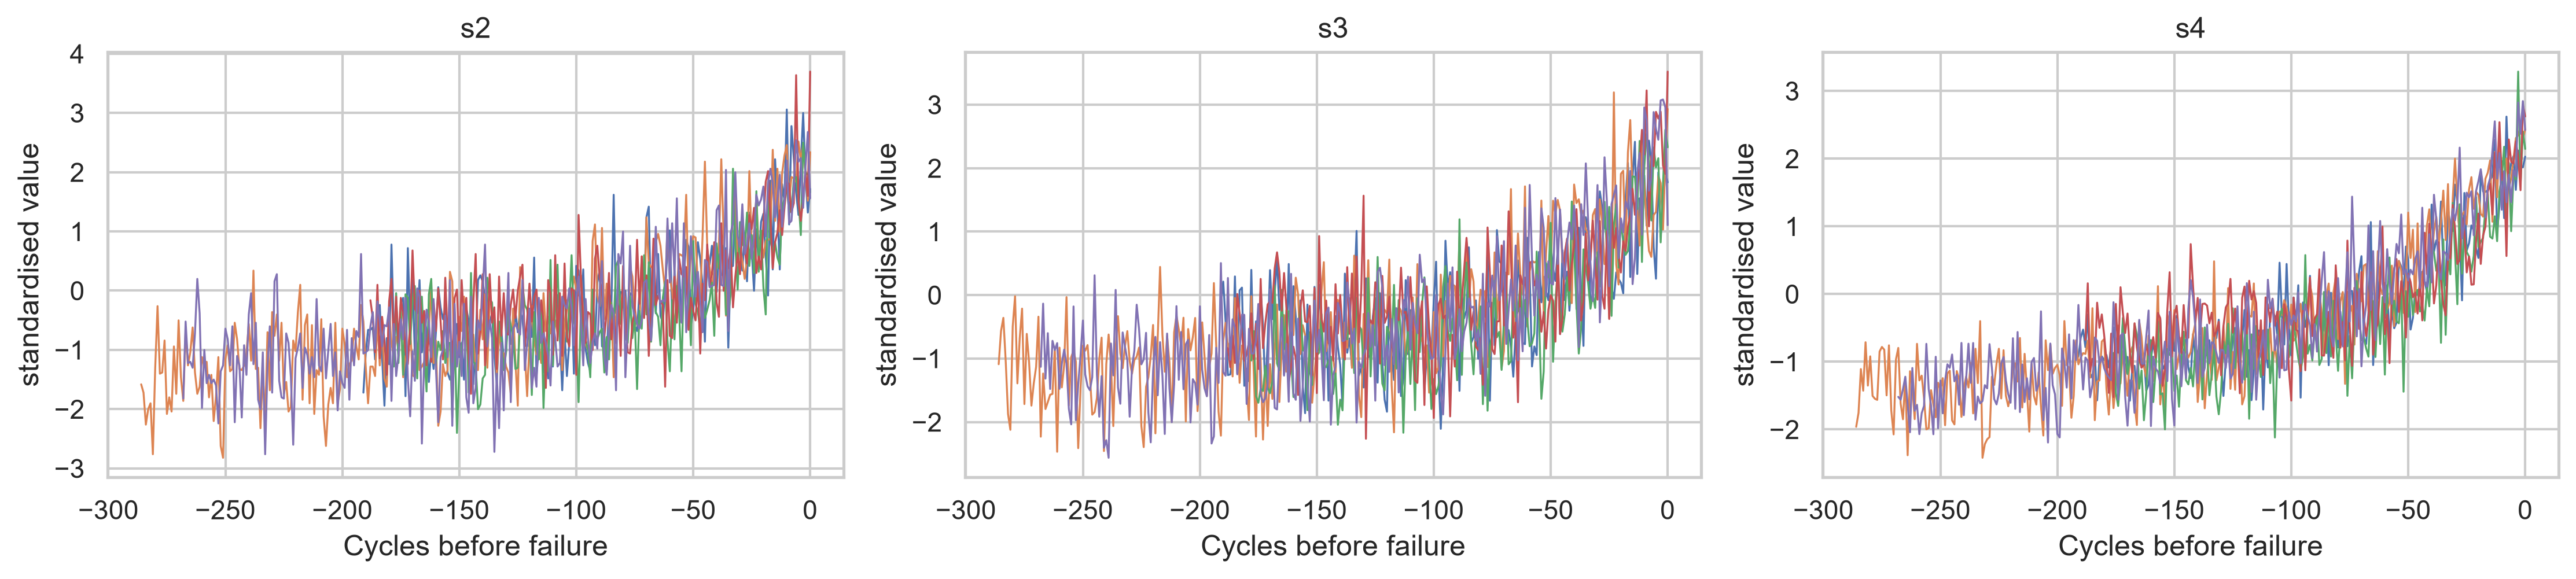

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, s in zip(axes, sensors[:3]):
    for u in [1, 2, 3, 4, 5]:
        g = train[train.unit == u]
        ax.plot(g["cycle"] - g["cycle"].max(), g[s], lw=0.8)
    ax.set(title=s, xlabel="Cycles before failure", ylabel="standardised value")
plt.tight_layout(); plt.show()

Plotted against the cycles *before failure*, several sensors show a clear trend that accelerates towards the end of life – the degradation signature the network must learn. Some sensors are constant in FD001 and were removed.

In [4]:
#| code-fold: false
L = 30   # window length (cycles)

def windows(df, with_target=True):
    X, y = [], []
    for _, g in df.groupby("unit"):
        v = g[sensors].values
        if len(v) < L:                                   # pad short test series
            v = np.vstack([np.repeat(v[:1], L - len(v), axis=0), v])
        if with_target:
            r = g["rul"].values
            for end in range(L, len(v) + 1):
                X.append(v[end - L:end]); y.append(r[end - 1])
        else:
            X.append(v[-L:])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

X_tr, y_tr = windows(train)
X_te, _ = windows(test, with_target=False)
X_tr.shape, X_te.shape

((17731, 30, 15), (100, 30, 15))

In [5]:
#| code-fold: false
torch.manual_seed(0)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(L * len(sensors), 64), nn.ReLU(),
    nn.Linear(64, 32), nn.ReLU(),
    nn.Linear(32, 1),
)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

Xt, yt = torch.tensor(X_tr), torch.tensor(y_tr).unsqueeze(1)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xt, yt),
                                     batch_size=256, shuffle=True)
history = []
for epoch in range(30):
    model.train()
    epoch_loss = 0.0
    for xb, yb in loader:
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        opt.step()
        epoch_loss += loss.item() * len(xb)
    history.append(epoch_loss / len(Xt))

model.eval()
with torch.no_grad():
    pred = model(torch.tensor(X_te)).squeeze().numpy()
rmse = np.sqrt(np.mean((pred - np.minimum(rul_test, 125))**2))
print(f"Test RMSE: {rmse:.1f} cycles")

Test RMSE: 15.2 cycles


The training loop is the same in every PyTorch project: forward pass, loss, `backward()` to compute gradients, `step()` to update the weights. The network has a few tens of thousands of weights – small by deep learning standards.

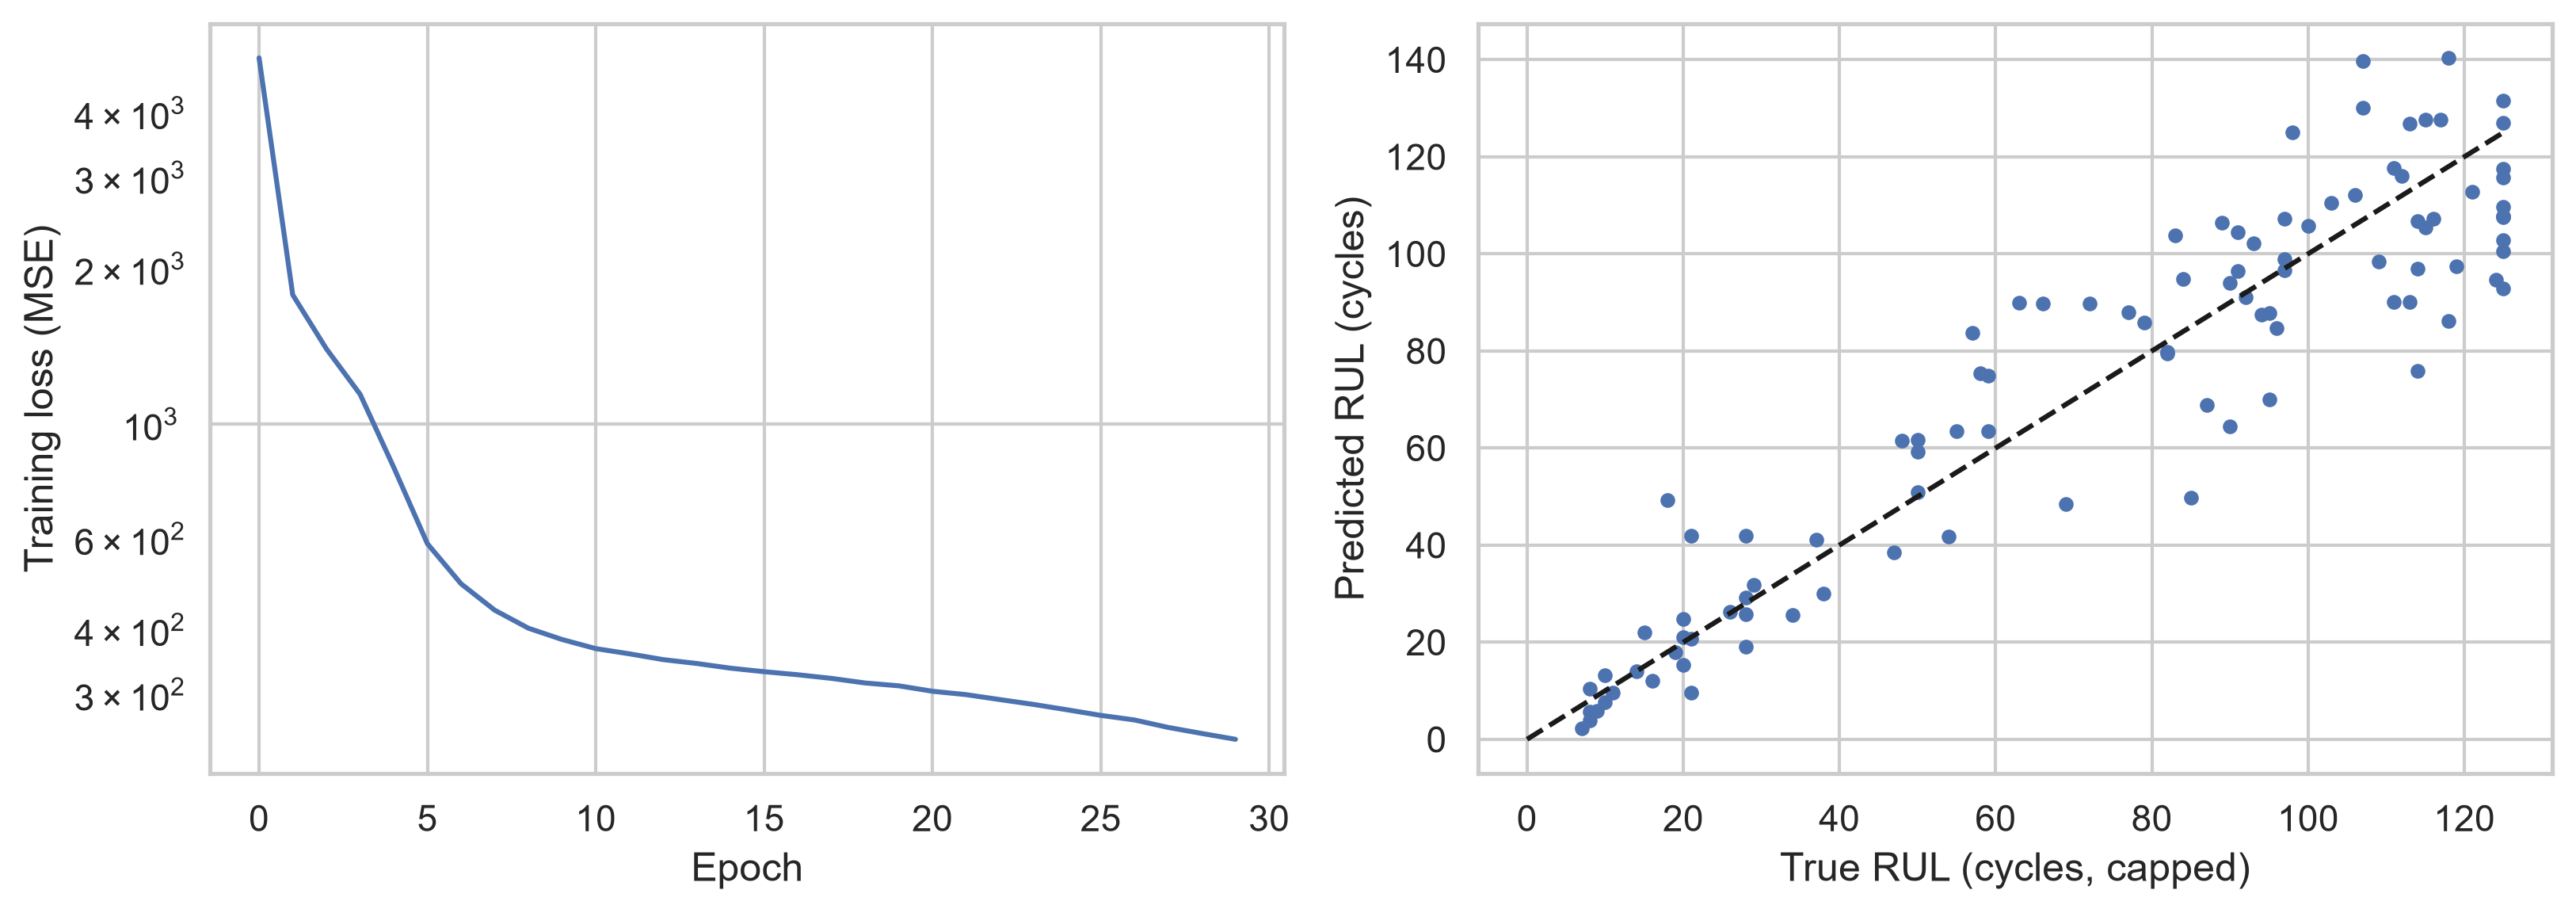

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history); axes[0].set(xlabel="Epoch", ylabel="Training loss (MSE)", yscale="log")
axes[1].scatter(np.minimum(rul_test, 125), pred, s=12)
axes[1].plot([0, 125], [0, 125], "k--")
axes[1].set(xlabel="True RUL (cycles, capped)", ylabel="Predicted RUL (cycles)")
plt.tight_layout(); plt.show()

**Discussion.** The predictions follow the diagonal, with larger scatter at high RUL, where degradation is barely visible, and smaller scatter near the end of life – fortunately the region where accurate predictions matter most. The training loss alone says nothing about overfitting; we did not use a validation set here (Exercise 2 fixes this). Also note that the test RMSE is computed on only 100 engines and therefore has considerable uncertainty itself. Whether the network beats a gradient boosting model on window statistics is an open question – Exercise 1.

## Back to the decision

An engine is scheduled too late if the model **overestimates** its RUL. If we schedule an overhaul when *predicted RUL − margin* falls below the planning horizon, the margin must cover the overestimates of 95 % of the engines – i.e. it must equal the 95 % quantile of the prediction error $\hat y - y$ on the test engines.

In [7]:
#| code-fold: false
true_rul = np.minimum(rul_test, 125)
err = pred - true_rul                                   # > 0: overestimate (dangerous)
margin = max(0.0, float(np.quantile(err, 0.95)))
print(f"Overestimated engines: {(err > 0).mean():.0%}, 95 % quantile of the error: {np.quantile(err, 0.95):.1f} cycles")
print(f"Decision: schedule an overhaul when the predicted RUL falls below 20 + {margin:.0f} = {20 + margin:.0f} cycles.")

Overestimated engines: 50%, 95 % quantile of the error: 23.9 cycles
Decision: schedule an overhaul when the predicted RUL falls below 20 + 24 = 44 cycles.


The margin is the price of the model's uncertainty: the more accurate the model, the smaller the margin and the more useful life is used. Note that the quantile is estimated from only 100 test engines – the fleet manager should add a reserve and refine the margin with field experience. And as in Chapter 3: C-MAPSS is a simulation, so the procedure must be validated on real engine data before it replaces the fixed interval.

## Extension: CNNs and transfer learning for visual inspection

*Extension – optional material, not required for the exam.*

**Convolutional neural networks (CNNs)** process images with small learnable filters (e.g. 3 × 3 pixels) that slide across the image. Early layers detect edges and simple textures, deeper layers combine them into complex patterns. Because the same filter is applied everywhere, CNNs need far fewer weights than an MLP on raw pixels.

Training a CNN from scratch requires many thousands of labelled images. **Transfer learning** avoids this: a network pretrained on millions of everyday images (ImageNet) already provides general visual features that transfer surprisingly well to industrial images. For anomaly detection, a simple but strong approach is: embed all good training images with the pretrained CNN and score a test image by its distance to the nearest good image in this feature space. No defective images are needed for training.

### Live coding: anomaly detection on one MVTec category

**Data access.** MVTec AD is free for non-commercial use (CC BY-NC-SA 4.0) and is downloaded from the MVTec website after accepting the license. Download one category (e.g. `bottle`, a few hundred MB) and extract it to `data/mvtec/bottle/`. A GPU (Colab: *Runtime → Change runtime type*) speeds things up but is not required. Because of the manual download, the two MVTec cells are **not executed** when the script is built – run them yourself after downloading the data.

In [8]:
#| eval: false
#| code-fold: false
from pathlib import Path
from torchvision import models
from PIL import Image

ROOT = Path("data/mvtec/bottle")
device = "cuda" if torch.cuda.is_available() else "cpu"

weights = models.ResNet18_Weights.DEFAULT
backbone = models.resnet18(weights=weights)
backbone.fc = torch.nn.Identity()           # use the 512-d feature vector
backbone.eval().to(device)
tf = weights.transforms()

@torch.no_grad()
def embed(paths):
    feats = []
    for p in paths:
        x = tf(Image.open(p).convert("RGB")).unsqueeze(0).to(device)
        feats.append(backbone(x).cpu().numpy()[0])
    return np.array(feats)

train_paths = sorted((ROOT / "train" / "good").glob("*.png"))
test_paths = sorted((ROOT / "test").glob("*/*.png"))
labels = np.array([p.parent.name != "good" for p in test_paths])
F_train, F_test = embed(train_paths), embed(test_paths)

In [9]:
#| eval: false
#| code-fold: false
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score

nn_model = NearestNeighbors(n_neighbors=1).fit(F_train)
score = nn_model.kneighbors(F_test)[0][:, 0]
print(f"Image-level ROC AUC: {roc_auc_score(labels, score):.3f}")

order = np.argsort(score)[::-1][:5]
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, i in zip(axes, order):
    ax.imshow(Image.open(test_paths[i])); ax.axis("off")
    ax.set_title(f"{test_paths[i].parent.name}\nscore {score[i]:.1f}")
plt.show()

The five most anomalous test images should mostly be defective bottles. State-of-the-art methods (e.g. PatchCore) refine this idea by comparing local image patches instead of whole images, which also localises the defect.

## Outlook

- **Physics-informed machine learning:** physical laws enter the model as constraints or as terms of the loss function – useful when data are scarce and extrapolation matters.
- **Surrogate models:** neural networks or Gaussian processes replace expensive FEM or CFD simulations in optimisation loops.
- **Foundation models:** large pretrained models for time series, images and text, adapted to specific tasks with little data; large language models as assistants for coding and documentation.
- **Deployment and MLOps:** models in production must be monitored for *data drift* (the input data change, e.g. a new sensor or a new product), retrained, versioned and – in safety-relevant applications – validated and certified.

::: {.callout-important}
## Key takeaways
- A neural network is a stack of linear maps and nonlinear activations, trained by gradient descent with backpropagation.
- Monitor a validation set and stop early; split by unit (engine, machine), not by window.
- For RUL prediction, sliding windows and a capped target are standard; errors near end of life matter most.
- Deep learning shines on raw images, signals and text; for tabular features, compare with gradient boosting first.
:::

## Exercises

<div class="exercises">

1. Build a baseline: gradient boosting on features of each window (last value, mean and slope of each sensor). Is the neural network better?
2. Hold out 20 training engines as a validation set (split by engine, not by window!) and implement early stopping. Plot training and validation loss.
3. Why is an *underestimate* of the RUL less critical than an overestimate? Design an asymmetric loss function and discuss its effect.
4. (Extension) Replace the MLP by a 1D convolutional network (`nn.Conv1d`). Mind the tensor shape (batch, channels, time).
5. (Extension) MVTec: repeat the anomaly detection for a texture category (e.g. `carpet`) and an object category (e.g. `screw`). Where does the method work better? Choose a threshold so that no defective part passes – what fraction of good parts is rejected?

</div>

### Solutions

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 1

In [10]:
#| code-fold: false
from sklearn.ensemble import HistGradientBoostingRegressor

def window_features(Xw):
    t = np.arange(L) - (L - 1) / 2
    slope = (Xw * t[None, :, None]).sum(axis=1) / (t**2).sum()
    return np.hstack([Xw[:, -1, :], Xw.mean(axis=1), slope])

gb = HistGradientBoostingRegressor(random_state=0).fit(window_features(X_tr), y_tr)
pred_gb = gb.predict(window_features(X_te))
rmse_gb = np.sqrt(np.mean((pred_gb - np.minimum(rul_test, 125))**2))
print(f"Test RMSE: MLP {rmse:.1f} cycles, gradient boosting {rmse_gb:.1f} cycles")

Test RMSE: MLP 15.2 cycles, gradient boosting 12.5 cycles


With well-chosen window features (level, mean and trend per sensor), gradient boosting is often on par with a small MLP on FD001 – a reminder that deep learning is not automatically better on sensor data with few channels. Neural networks gain an advantage on the more complex subsets (FD002/FD004 with six operating conditions) and with architectures that exploit the sequence structure, such as 1D CNNs or LSTMs.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 2

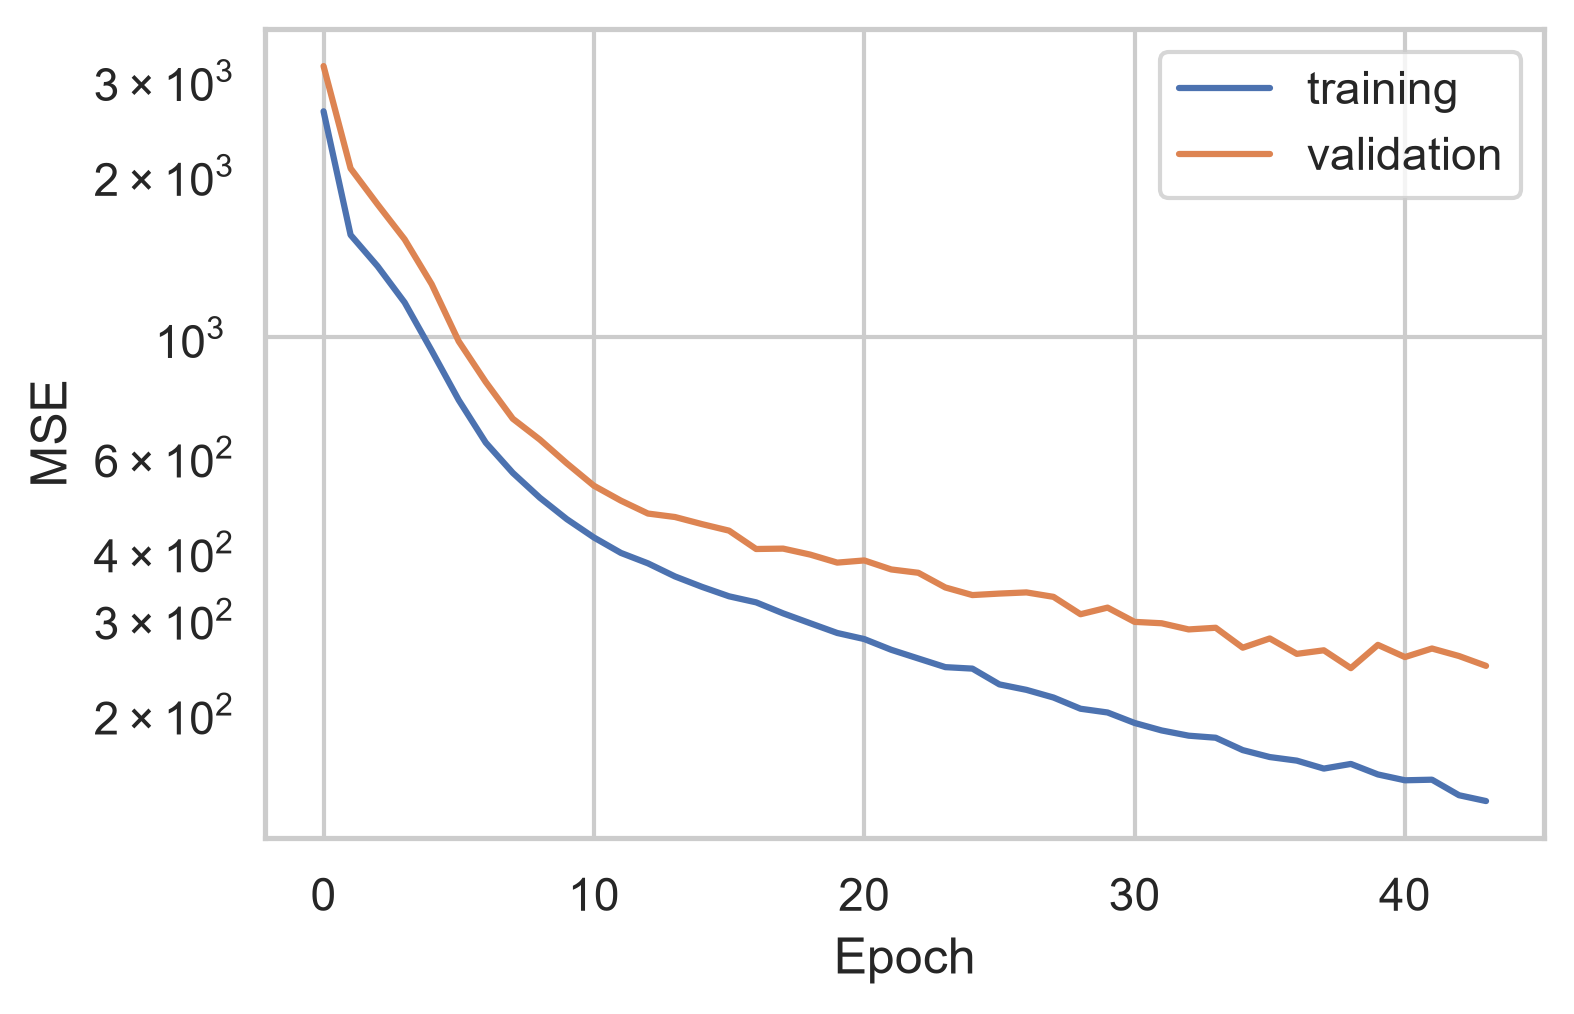

stopped after 44 epochs, best validation RMSE 15.6 cycles


In [11]:
#| code-fold: false
rng = np.random.default_rng(0)
val_units = rng.choice(train["unit"].unique(), size=20, replace=False)
Xa, ya = windows(train[~train.unit.isin(val_units)])
Xv, yv = windows(train[train.unit.isin(val_units)])
Xa_t, ya_t = torch.tensor(Xa), torch.tensor(ya).unsqueeze(1)
Xv_t, yv_t = torch.tensor(Xv), torch.tensor(yv).unsqueeze(1)

def make_mlp():
    return nn.Sequential(nn.Flatten(), nn.Linear(L * len(sensors), 64), nn.ReLU(),
                         nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))

torch.manual_seed(0)
net, best, best_state, patience, wait = make_mlp(), np.inf, None, 5, 0
opt2 = torch.optim.Adam(net.parameters(), lr=1e-3)
dl = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xa_t, ya_t), batch_size=256, shuffle=True)
tr_hist, va_hist = [], []
for epoch in range(100):
    net.train()
    for xb, yb in dl:
        opt2.zero_grad(); l = loss_fn(net(xb), yb); l.backward(); opt2.step()
    net.eval()
    with torch.no_grad():
        tr_hist.append(loss_fn(net(Xa_t), ya_t).item()); va_hist.append(loss_fn(net(Xv_t), yv_t).item())
    if va_hist[-1] < best:
        best, best_state, wait = va_hist[-1], {k: v.clone() for k, v in net.state_dict().items()}, 0
    else:
        wait += 1
        if wait >= patience:
            break
net.load_state_dict(best_state)
plt.plot(tr_hist, label="training"); plt.plot(va_hist, label="validation")
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()
print(f"stopped after {len(va_hist)} epochs, best validation RMSE {np.sqrt(best):.1f} cycles")

The validation loss typically decreases at first and then flattens or rises while the training loss keeps falling – overfitting. Early stopping keeps the weights of the best validation epoch. Splitting by engine is essential: with a random window split, validation windows would be near-copies of training windows from the same engine, and the validation loss would keep falling.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 3
An underestimate leads to maintenance too early: some useful life is wasted, a cost that can be planned. An overestimate means the machine may fail before maintenance: unplanned downtime, secondary damage, possibly a safety risk. An asymmetric loss penalises late predictions (predicted RUL > true RUL) more strongly, e.g. the score of the PHM 2008 challenge with $d = \hat y - y$:
$$s(d) = \begin{cases} e^{-d/13} - 1, & d < 0 \\ e^{d/10} - 1, & d \ge 0. \end{cases}$$
A simpler differentiable variant for training is a weighted squared error:

In [12]:
#| code-fold: false
def asymmetric_mse(pred, target, w_late=4.0):
    d = pred - target
    return torch.mean(torch.where(d > 0, w_late * d**2, d**2))

Training with such a loss shifts the predictions towards lower RUL values – the model becomes deliberately conservative. The weight should reflect the real cost ratio of late and early maintenance.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 4

In [13]:
#| code-fold: false
class CNN1D(nn.Module):
    def __init__(self, n_sensors):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(n_sensors, 32, kernel_size=5, padding=2), nn.ReLU(),
            nn.Conv1d(32, 32, kernel_size=5, padding=2), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(32, 1))

    def forward(self, x):                  # x: (batch, time, sensors)
        return self.net(x.transpose(1, 2))  # Conv1d expects (batch, channels, time)

torch.manual_seed(0)
cnn = CNN1D(len(sensors))
opt3 = torch.optim.Adam(cnn.parameters(), lr=1e-3)
for epoch in range(30):
    cnn.train()
    for xb, yb in loader:
        opt3.zero_grad(); l = loss_fn(cnn(xb), yb); l.backward(); opt3.step()
cnn.eval()
with torch.no_grad():
    pred_cnn = cnn(torch.tensor(X_te)).squeeze().numpy()
print(f"Test RMSE 1D CNN: {np.sqrt(np.mean((pred_cnn - np.minimum(rul_test, 125))**2)):.1f} cycles")

Test RMSE 1D CNN: 18.2 cycles


The convolution filters slide along the time axis and share their weights over time, so the network detects local patterns (e.g. a steepening trend) wherever they occur in the window. The sensors are the input *channels* – hence the transposition from (batch, time, sensors) to (batch, sensors, time).
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 5
Change `ROOT` to the new category and rerun the two cells. Image-level anomaly detection with global features typically works very well for objects with consistent appearance (bottle) and for many textures, but less well for categories with small, local defects on objects with varying pose (screw), because a global feature vector averages over the whole image. For a threshold that lets no defective part pass:

In [14]:
#| code-fold: false
#| eval: false
thr = score[labels].min()                          # lowest score among defective images
false_reject = (score[~labels] >= thr).mean()
print(f"threshold {thr:.2f}: {false_reject:.0%} of good parts rejected")

The resulting false reject rate shows the price of zero slip. Note that this threshold was chosen on the test set itself and is therefore optimistic; in practice it must be set on separate validation images.
:::